# Pass-interception survival model

**Analytical question:** Assess a hypothetical passing option.

**Stages in this notebook:** Ball path and timing; player arrival; interception hazard; survival integration.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Specify the hypothetical pass

Prepare real player coordinates, then choose a start and destination before computing interception.

,player_id,x,y,x_previous,y_previous
0,11897,-23.76,-8.98,-23.58,-9.12
1,287934,5.39,5.03,5.52,5.14
2,50982,-25.71,23.32,-25.47,23.19
3,50999,36.45,0.86,36.52,0.89
4,51002,-4.41,1.65,-4.07,1.49


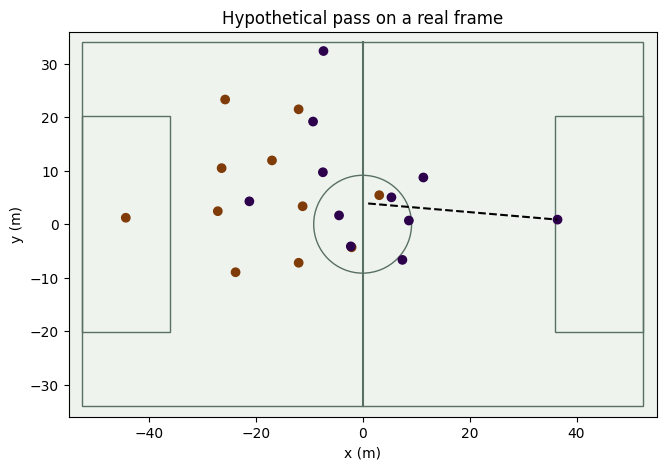

In [4]:
X,Y=np.meshgrid(np.linspace(-52.5,52.5,70),np.linspace(-34,34,46));targets=np.stack([X,Y],axis=-1)
nodes=snapshot.reset_index(drop=True);positions=nodes[['x','y']].to_numpy();home=nodes.team_id.eq(1802).to_numpy()
previous=observed[observed.frame_id.eq(frame_id-1)][['player_id','x','y','seconds']]
nodes=nodes.merge(previous,on='player_id',suffixes=('','_previous'),how='left');dt=nodes.seconds-nodes.seconds_previous
velocity=(nodes[['x','y']].to_numpy()-nodes[['x_previous','y_previous']].to_numpy())/dt.to_numpy()[:,None]
velocity=np.nan_to_num(velocity,nan=0.,posinf=0.,neginf=0.)
display(nodes[['player_id','x','y','x_previous','y_previous']].head())

ball=wide[wide.frame_id.eq(frame_id)].iloc[0];start=np.array([ball.ball_x,ball.ball_y]);options=nodes[nodes.team_id.eq(1802)].copy()
destination=options.loc[np.hypot(options.x-start[0],options.y-start[1]).idxmax(),['x','y']].to_numpy(dtype=float)
fig,ax=plt.subplots(figsize=(9,5));pitch(ax);ax.scatter(positions[:,0],positions[:,1],c=home,cmap='PuOr');ax.plot([start[0],destination[0]],[start[1],destination[1]],'k--');ax.set_title('Hypothetical pass on a real frame');plt.show()

## 5. Inspect ball travel and player arrival

Introduce the component calculator before using it. First inspect only the competing arrival times.

,ball_time_s,earliest_defender_arrival_s
0,0.000000,1.218802
1,0.060767,1.101081
2,0.121533,1.045026
3,0.182300,1.079059
4,0.243067,1.184557
5,0.303833,1.326396
6,0.364600,1.485121
7,0.425367,1.652326
8,0.486134,1.824234
9,0.546900,1.998978


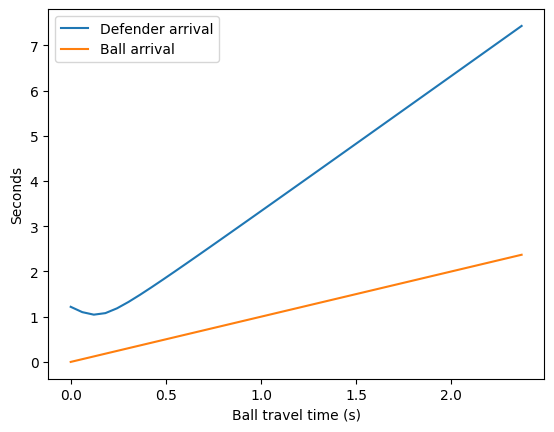

In [5]:
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-40,40)))

def interception_components(start,end,defenders,ball_speed=15.,reaction=.7,run_speed=5.,rate=2.):
    duration=np.linalg.norm(end-start)/ball_speed
    times=np.linspace(0,max(duration,1e-6),40)
    path=start+(end-start)*np.linspace(0,1,40)[:,None]
    player_arrival=reaction+np.linalg.norm(path[:,None,:]-defenders[None,:,:],axis=-1)/run_speed
    hazard=rate*sigmoid((times[:,None]-player_arrival)/.15)
    increments=(hazard.sum(axis=1)[1:]+hazard.sum(axis=1)[:-1])/2*np.diff(times)
    survival=np.exp(-np.r_[0,np.cumsum(increments)])
    return times,player_arrival,hazard,survival
times,player_arrival,hazard,survival=interception_components(start,destination,positions[~home])
display(pd.DataFrame({'ball_time_s':times,'earliest_defender_arrival_s':player_arrival.min(axis=1)}).head(12))
plt.plot(times,player_arrival.min(axis=1),label='Defender arrival');plt.plot(times,times,label='Ball arrival');plt.xlabel('Ball travel time (s)');plt.ylabel('Seconds');plt.legend();plt.show()

## 6. Calculate local interception hazards

The arrival-time difference feeds a sigmoid hazard. Sum defender hazards before integrating them.

,0,1,2,3,4,5,6,7,8,9,10
0,8.496709e-18,8.496709e-18,7.361365e-14,1.585236e-07,8.496709e-18,2.420800e-12,8.496709e-18,1.494369e-09,8.496709e-18,0.000592,3.976562e-15
1,8.496709e-18,8.496709e-18,3.493891e-14,1.613912e-07,8.496709e-18,1.521145e-12,8.496709e-18,6.707649e-10,8.496709e-18,0.001944,2.636293e-15
2,8.496709e-18,8.496709e-18,1.649389e-14,1.477740e-07,8.496709e-18,9.281610e-13,8.496709e-18,3.007240e-10,8.496709e-18,0.004230,1.702380e-15
3,8.496709e-18,8.496709e-18,7.749470e-15,1.231487e-07,8.496709e-18,5.516563e-13,8.496709e-18,1.346929e-10,8.496709e-18,0.005053,1.073017e-15
4,8.496709e-18,8.496709e-18,3.625676e-15,9.453349e-08,8.496709e-18,3.202617e-13,8.496709e-18,6.027981e-11,8.496709e-18,0.003752,6.614272e-16


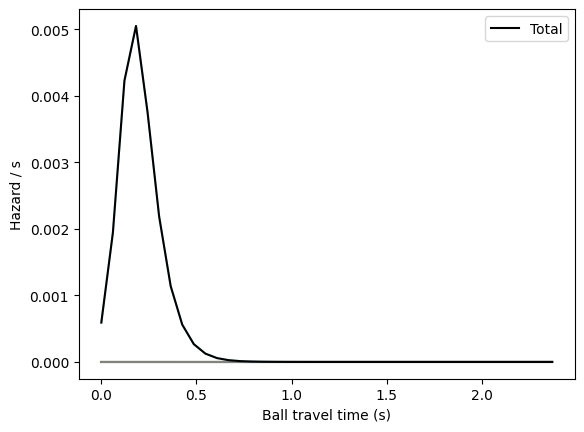

In [6]:
display(pd.DataFrame(hazard).head())
plt.plot(times,hazard,alpha=.3);plt.plot(times,hazard.sum(axis=1),c='black',label='Total');plt.xlabel('Ball travel time (s)');plt.ylabel('Hazard / s');plt.legend();plt.show()

## 7. Integrate survival along the path

Inspect the progressive no-interception probability before selecting its endpoint value.

,ball_time_s,total_hazard,survival
0,0.000000,0.000592,1.000000
1,0.060767,0.001944,0.999923
2,0.121533,0.004230,0.999735
3,0.182300,0.005053,0.999453
4,0.243067,0.003753,0.999186
5,0.303833,0.002187,0.999006
6,0.364600,0.001139,0.998905
7,0.425367,0.000560,0.998853
8,0.486134,0.000267,0.998828
9,0.546900,0.000125,0.998816


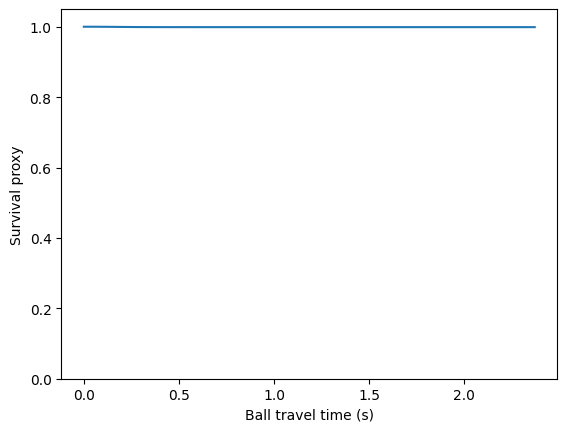

In [7]:
display(pd.DataFrame({'ball_time_s':times,'total_hazard':hazard.sum(axis=1),'survival':survival}).head(12))
plt.plot(times,survival);plt.ylim(0,1.05);plt.xlabel('Ball travel time (s)');plt.ylabel('Survival proxy');plt.show()

## 8. Final output: compare passing options

Reuse the inspected component calculator for every hypothetical teammate destination.

,player_id,x,y,completion_proxy
4,51002,-4.41,1.65,0.999949
8,560882,-7.43,9.72,0.999895
9,560983,7.44,-6.67,0.999853
6,51050,8.65,0.69,0.999493
3,50999,36.45,0.86,0.998806
1,287934,5.39,5.03,0.997385
19,965697,11.36,8.74,0.995116
5,51043,-7.32,32.39,0.993757
17,797298,-9.27,19.20,0.978780
12,560986,-2.21,-4.14,0.977163


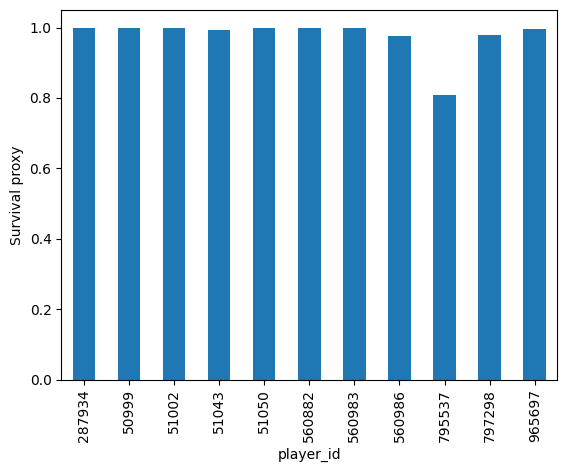

In [8]:
def completion_proxy(start,end,defenders):
    if np.linalg.norm(end-start)<1e-9:return 1.
    return float(interception_components(start,end,defenders)[-1][-1])
options['completion_proxy']=[completion_proxy(start,np.array([r.x,r.y]),positions[~home]) for r in options.itertuples()]
display(options[['player_id','x','y','completion_proxy']].sort_values('completion_proxy',ascending=False));assert options.completion_proxy.between(0,1).all()
options.plot.bar(x='player_id',y='completion_proxy',legend=False);plt.ylabel('Survival proxy');plt.show()

## Interpretation and limitations

This is an independent-hazard teaching model with assumed ball speed and player movement. It is not calibrated pass completion, exact Spearman control, or the published accessible-space implementation. Destinations are hypothetical, not observed attempts.